# Modul 2: Eindimensionale Systeme

---

## Das Labor für Intuition

Eindimensionale Systeme sind das perfekte Trainingsfeld. Nicht weil sie trivial sind, sondern weil sie **vollständig verstehbar** sind.

In 1D kannst du:
- Das gesamte Langzeitverhalten aus einer Skizze ablesen
- Stabilität ohne Rechnung bestimmen
- Verstehen, warum manche Verhaltensweisen *unmöglich* sind

Die Intuition, die du hier entwickelst, trägt dich durch alle höheren Dimensionen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.optimize import fsolve

plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 100,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'lines.linewidth': 2,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

%matplotlib inline

---

## 2.1 Die grafische Methode

Gegeben: $\dot{x} = f(x)$

**Der Algorithmus:**

1. Zeichne $f(x)$ als Funktion
2. Wo $f(x) = 0$ → **Fixpunkte**
3. Wo $f(x) > 0$ → $x$ wächst (Pfeil nach rechts)
4. Wo $f(x) < 0$ → $x$ schrumpft (Pfeil nach links)
5. Lies das Langzeitverhalten ab

Das ist alles. Keine Integration nötig.

In [2]:
def analyze_1d_system(f, x_range, title="", ax=None):
    """
    Vollständige grafische Analyse eines 1D-Systems.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 6))
    
    x = np.linspace(x_range[0], x_range[1], 1000)
    y = np.array([f(xi) for xi in x])
    
    # Plot f(x)
    ax.plot(x, y, 'b-', linewidth=2.5, label=r'$f(x) = \dot{x}$')
    ax.axhline(y=0, color='k', linewidth=1)
    ax.axvline(x=0, color='k', linewidth=0.5, alpha=0.5)
    
    # Färbe Regionen
    ax.fill_between(x, y, 0, where=(y > 0), alpha=0.15, color='green')
    ax.fill_between(x, y, 0, where=(y < 0), alpha=0.15, color='red')
    
    # Finde Fixpunkte (Nullstellen)
    sign_changes = np.where(np.diff(np.sign(y)))[0]
    fixed_points = []
    
    for idx in sign_changes:
        # Lineare Interpolation für genauere Position
        x_star = x[idx] - y[idx] * (x[idx+1] - x[idx]) / (y[idx+1] - y[idx])
        
        # Stabilität: Vorzeichen der Ableitung
        h = 1e-6
        df = (f(x_star + h) - f(x_star - h)) / (2 * h)
        
        is_stable = df < 0
        fixed_points.append((x_star, is_stable))
        
        if is_stable:
            ax.plot(x_star, 0, 'ko', markersize=15, zorder=5)
        else:
            ax.plot(x_star, 0, 'ko', markersize=15, fillstyle='none', 
                   markeredgewidth=3, zorder=5)
    
    # Fluss-Pfeile
    y_arrow = ax.get_ylim()[0] * 0.15
    for xi in np.linspace(x_range[0]*0.9, x_range[1]*0.9, 30):
        fi = f(xi)
        if abs(fi) > 0.05 * max(abs(y)):
            direction = 0.08 * (x_range[1] - x_range[0]) * np.sign(fi)
            ax.annotate('', xy=(xi + direction, y_arrow), xytext=(xi, y_arrow),
                       arrowprops=dict(arrowstyle='->', color='darkgreen' if fi > 0 else 'darkred', lw=1.5))
    
    ax.set_xlabel(r'$x$', fontsize=14)
    ax.set_ylabel(r'$\dot{x} = f(x)$', fontsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(loc='upper right')
    
    # Legende für Fixpunkte
    ax.plot([], [], 'ko', markersize=10, label='Stabil')
    ax.plot([], [], 'ko', markersize=10, fillstyle='none', markeredgewidth=2, label='Instabil')
    ax.legend()
    
    return fixed_points


Fixpunkte:
  x* = 0.000 (instabil)
  x* = 1.000 (stabil)


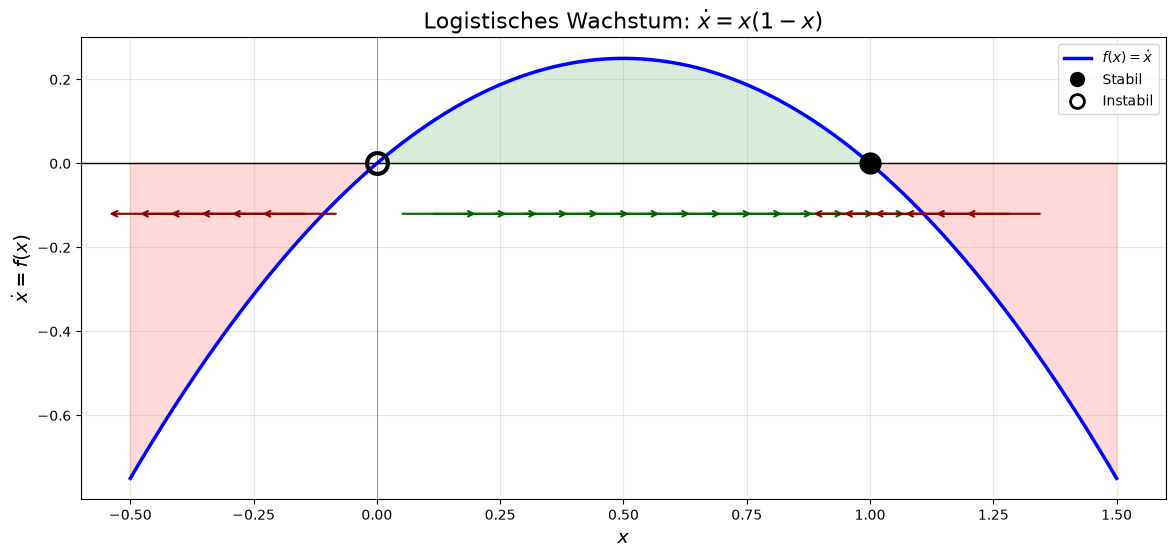

In [3]:
# Beispiel 1: Logistisches Wachstum
# ẋ = rx(1 - x/K) mit r=1, K=1 → ẋ = x(1-x)

def logistic(x):
    return x * (1 - x)

fps = analyze_1d_system(logistic, (-0.5, 1.5), 
                        title=r'Logistisches Wachstum: $\dot{x} = x(1-x)$')

print("\nFixpunkte:")
for x_star, stable in fps:
    status = "stabil" if stable else "instabil"
    print(f"  x* = {x_star:.3f} ({status})")

plt.show()

### Interpretation

Das logistische Wachstumsmodell hat zwei Fixpunkte:

- $x^* = 0$: Instabil (Aussterben - aber jede kleine Population wächst weg)
- $x^* = 1$: Stabil (Kapazitätsgrenze - System konvergiert dorthin)

Die Pfeile zeigen: Von jedem Startwert $x_0 > 0$ läuft das System zu $x=1$. (Negative $x_0$ laufen nach $-\infty$ - als Populationsgrößen sind sie aber ohnehin bedeutungslos.)

**Das ist die Essenz der Tragfähigkeit** - ohne je die Lösung $x(t) = \frac{x_0 e^t}{1 + x_0(e^t - 1)}$ zu berechnen.


Fixpunkte:
  x* = -1.000 (stabil)
  x* = 0.000 (instabil)
  x* = 1.000 (stabil)


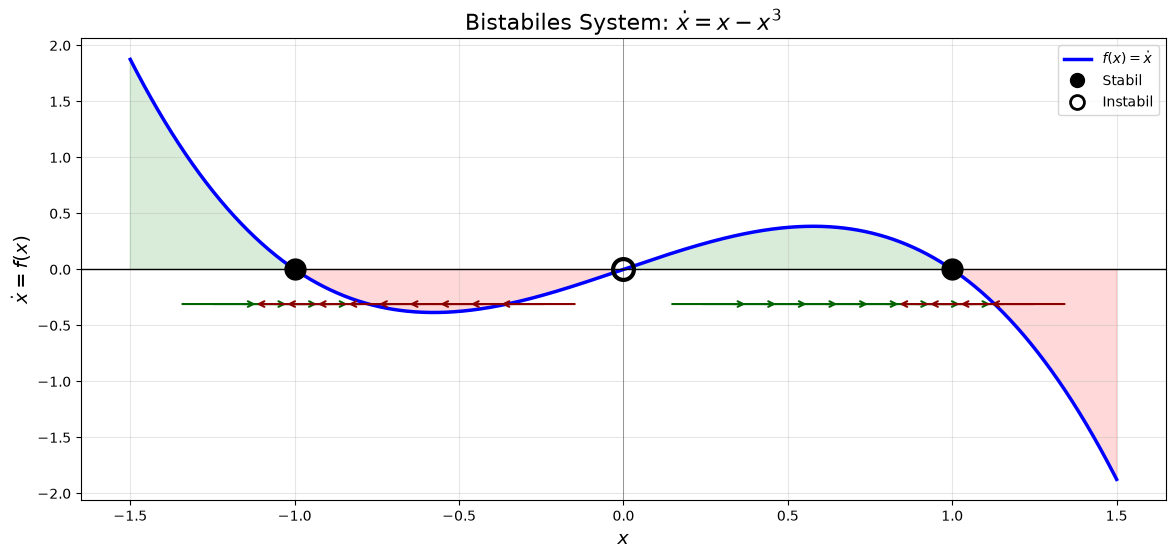

In [4]:
# Beispiel 2: Bistabilität
# ẋ = x - x³ = x(1-x)(1+x)

def bistable(x):
    return x - x**3

fps = analyze_1d_system(bistable, (-1.5, 1.5),
                        title=r'Bistabiles System: $\dot{x} = x - x^3$')

print("\nFixpunkte:")
for x_star, stable in fps:
    status = "stabil" if stable else "instabil"
    print(f"  x* = {x_star:.3f} ({status})")

plt.show()

### Bistabilität

Hier sehen wir **zwei stabile Zustände** ($x = \pm 1$) getrennt durch einen instabilen ($x = 0$).

Das Schicksal des Systems hängt von der Anfangsbedingung ab:
- $x_0 > 0 \Rightarrow x \to +1$
- $x_0 < 0 \Rightarrow x \to -1$
- $x_0 = 0 \Rightarrow$ bleibt bei 0 (aber instabil!)

Der Punkt $x = 0$ ist eine **Wasserscheide** - er trennt die Einzugsgebiete (basins of attraction) der beiden stabilen Zustände.

---

## 2.2 Stabilität: Die mathematische Definition

Ein Fixpunkt $x^*$ heißt:

**Stabil:** Kleine Störungen werden korrigiert. Formal: $\forall \epsilon > 0 \ \exists \delta > 0$ s.d. $|x_0 - x^*| < \delta \Rightarrow |x(t) - x^*| < \epsilon \ \forall t > 0$

**Asymptotisch stabil:** Stabil und $x(t) \to x^*$ für $t \to \infty$

**Instabil:** Nicht stabil (kleine Störungen wachsen)

### Das Linearisierungskriterium

Für $\dot{x} = f(x)$ mit Fixpunkt $x^*$ (also $f(x^*) = 0$):

$$\boxed{f'(x^*) < 0 \Rightarrow \text{asymptotisch stabil}}$$
$$\boxed{f'(x^*) > 0 \Rightarrow \text{instabil}}$$
$$f'(x^*) = 0 \Rightarrow \text{keine Aussage (höhere Ordnung nötig)}$$

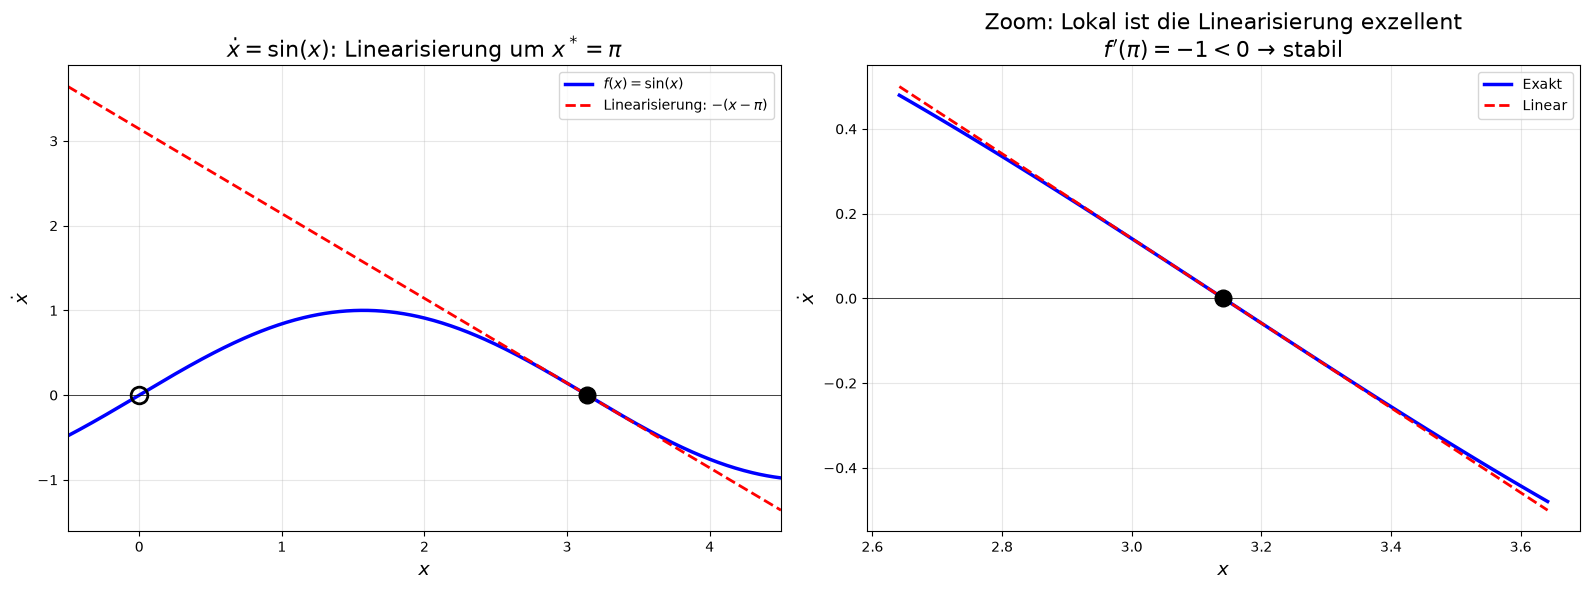

In [5]:
# Demonstration der Linearisierung

def demonstrate_linearization():
    """
    Zeigt, wie Linearisierung um einen Fixpunkt funktioniert.
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # System: ẋ = sin(x)
    def f(x):
        return np.sin(x)
    
    x = np.linspace(-0.5, 4.5, 500)
    
    # Fixpunkt x* = π
    x_star = np.pi
    
    # Taylorentwicklung um x*: f(x) ≈ f(x*) + f'(x*)(x - x*)
    # f(π) = 0, f'(π) = cos(π) = -1
    # Also: f(x) ≈ -1 · (x - π) = -(x - π)
    
    def f_linear(x):
        return -1 * (x - x_star)
    
    ax1 = axes[0]
    ax1.plot(x, f(x), 'b-', linewidth=2.5, label=r'$f(x) = \sin(x)$')
    ax1.plot(x, f_linear(x), 'r--', linewidth=2, label=r'Linearisierung: $-(x - \pi)$')
    ax1.axhline(y=0, color='k', linewidth=0.5)
    ax1.plot(0, 0, 'ko', markersize=12, fillstyle='none', markeredgewidth=2)
    ax1.plot(x_star, 0, 'ko', markersize=12)
    ax1.set_xlabel(r'$x$')
    ax1.set_ylabel(r'$\dot{x}$')
    ax1.set_title(r'$\dot{x} = \sin(x)$: Linearisierung um $x^* = \pi$')
    ax1.legend()
    ax1.set_xlim(-0.5, 4.5)
    
    # Zoom auf Fixpunkt
    ax2 = axes[1]
    x_zoom = np.linspace(x_star - 0.5, x_star + 0.5, 100)
    ax2.plot(x_zoom, np.sin(x_zoom), 'b-', linewidth=2.5, label='Exakt')
    ax2.plot(x_zoom, f_linear(x_zoom), 'r--', linewidth=2, label='Linear')
    ax2.axhline(y=0, color='k', linewidth=0.5)
    ax2.plot(x_star, 0, 'ko', markersize=12)
    ax2.set_xlabel(r'$x$')
    ax2.set_ylabel(r'$\dot{x}$')
    ax2.set_title(f"Zoom: Lokal ist die Linearisierung exzellent\n" +
                  r"$f'(\pi) = -1 < 0$ → stabil")
    ax2.legend()
    
    plt.tight_layout()
    return fig

demonstrate_linearization()
plt.show()

### Warum funktioniert die Linearisierung?

Setze $x = x^* + \epsilon$ (kleine Störung $\epsilon$):

$$\dot{\epsilon} = \dot{x} = f(x^* + \epsilon) \approx f(x^*) + f'(x^*) \cdot \epsilon = f'(x^*) \cdot \epsilon$$

(da $f(x^*) = 0$ am Fixpunkt)

Das ist eine lineare DGL: $\dot{\epsilon} = \lambda \epsilon$ mit $\lambda = f'(x^*)$

Lösung: $\epsilon(t) = \epsilon_0 e^{\lambda t}$

- $\lambda < 0$: Störung klingt ab → **stabil**
- $\lambda > 0$: Störung wächst → **instabil**

---

## 2.3 Potentiale: Das Ball-auf-Hügel-Bild

Für eine wichtige Klasse von Systemen gibt es eine noch elegantere Sichtweise.

**Gradientensystem:** $\dot{x} = f(x) = -\frac{dV}{dx}$ für eine Funktion $V(x)$

$V(x)$ heißt **Potential**. Das System "fällt bergab" in der Potentiallandschaft.

- Stabile Fixpunkte = lokale **Minima** von $V$
- Instabile Fixpunkte = lokale **Maxima** von $V$

In [6]:
def visualize_potential(V, x_range, title=""):
    """
    Visualisiert ein Potential und das zugehörige Gradientensystem.
    """
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), height_ratios=[1.5, 1])
    
    x = np.linspace(x_range[0], x_range[1], 500)
    v = np.array([V(xi) for xi in x])
    
    # Oberes Bild: Potentiallandschaft
    ax1 = axes[0]
    ax1.plot(x, v, 'b-', linewidth=3)
    ax1.fill_between(x, v, ax1.get_ylim()[0] if ax1.get_ylim()[0] < min(v) else min(v)-0.5, 
                     alpha=0.1, color='blue')
    
    # Finde Extrema
    h = 1e-6
    dv = np.array([(V(xi+h) - V(xi-h))/(2*h) for xi in x])
    d2v = np.array([(V(xi+h) - 2*V(xi) + V(xi-h))/h**2 for xi in x])
    
    sign_changes = np.where(np.diff(np.sign(dv)))[0]
    for idx in sign_changes:
        x_ext = x[idx]
        v_ext = V(x_ext)
        is_min = d2v[idx] > 0
        
        if is_min:
            ax1.plot(x_ext, v_ext, 'go', markersize=15, zorder=5)
            ax1.annotate('Minimum\n(stabil)', xy=(x_ext, v_ext), 
                        xytext=(x_ext, v_ext + 0.3), ha='center', fontsize=11)
        else:
            ax1.plot(x_ext, v_ext, 'ro', markersize=15, zorder=5)
            ax1.annotate('Maximum\n(instabil)', xy=(x_ext, v_ext),
                        xytext=(x_ext, v_ext + 0.3), ha='center', fontsize=11)
    
    # Ball
    ball_x = 0.7
    ball_y = V(ball_x)
    circle = plt.Circle((ball_x, ball_y + 0.08), 0.08, color='orange', zorder=10)
    ax1.add_patch(circle)
    ax1.annotate('', xy=(ball_x + 0.3, ball_y - 0.1), xytext=(ball_x + 0.1, ball_y),
                arrowprops=dict(arrowstyle='->', color='orange', lw=2))
    
    ax1.set_xlabel(r'$x$', fontsize=14)
    ax1.set_ylabel(r'$V(x)$', fontsize=14)
    ax1.set_title(f'Potentiallandschaft: {title}', fontsize=16)
    
    # Unteres Bild: Das zugehörige Vektorfeld
    ax2 = axes[1]
    f = lambda xi: -(V(xi+h) - V(xi-h))/(2*h)  # f = -dV/dx
    analyze_1d_system(f, x_range, title=r'Zugehöriges System: $\dot{x} = -dV/dx$', ax=ax2)
    
    plt.tight_layout()
    return fig

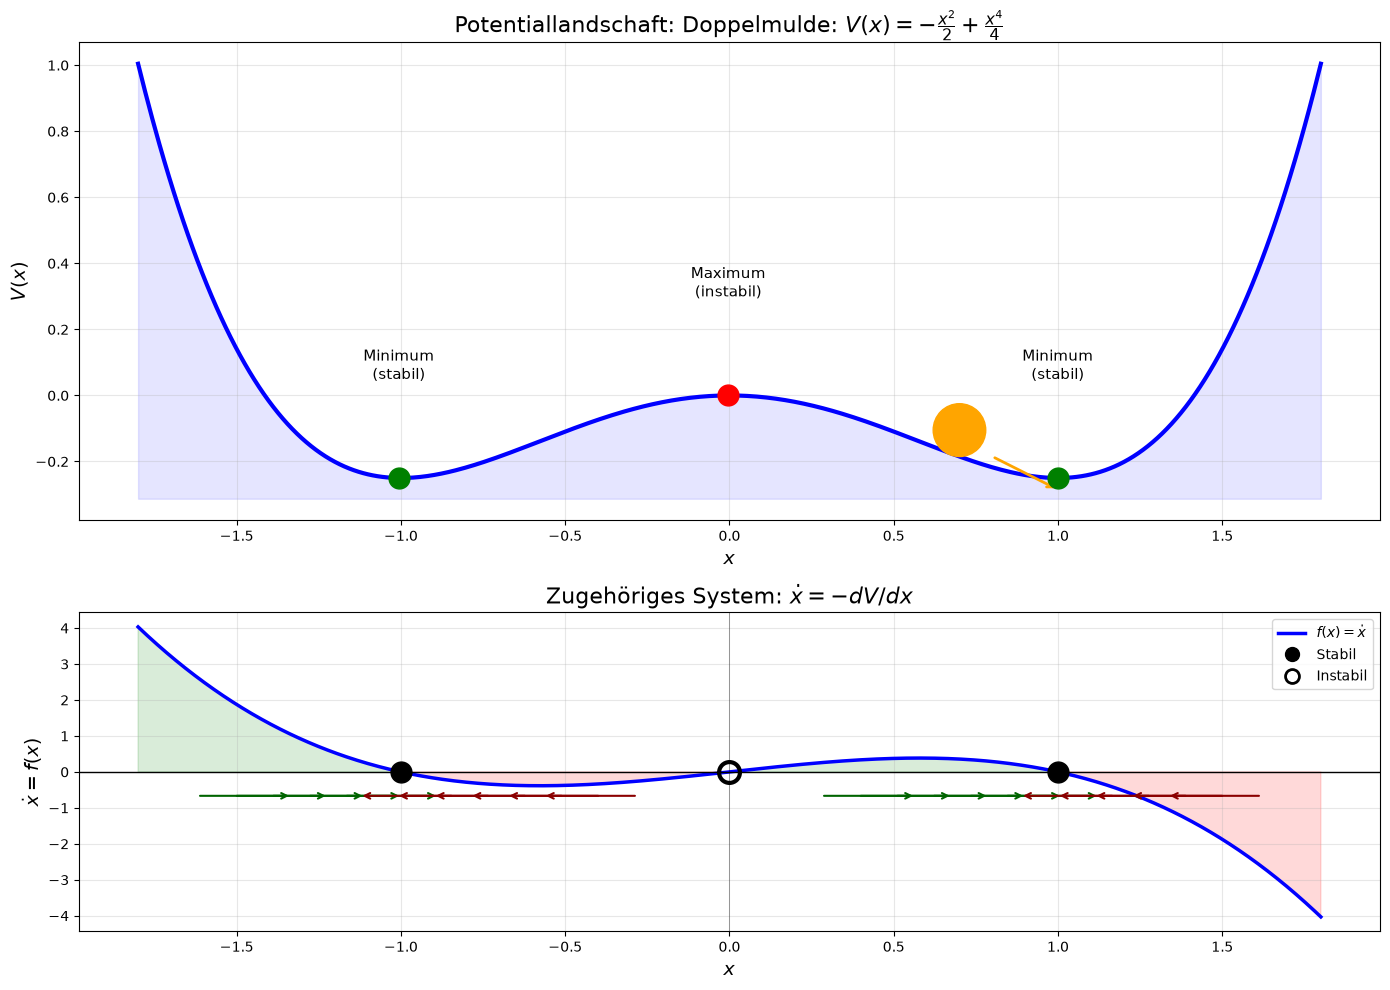

In [7]:
# Das Doppelmulden-Potential
# V(x) = -x²/2 + x⁴/4
# → ẋ = -V'(x) = x - x³

def double_well(x):
    return -x**2/2 + x**4/4

visualize_potential(double_well, (-1.8, 1.8), 
                    title=r'Doppelmulde: $V(x) = -\frac{x^2}{2} + \frac{x^4}{4}$')
plt.show()

### Die Doppelmulde: Ein Paradigma

Das Doppelmulden-Potential ist das Standardmodell für:

- **Phasenübergänge** (Magnetisierung, Symmetriebrechung)
- **Bistabile Schalter** (Biologische Schalter, Speicher)
- **Entscheidungsprozesse** (Zwei Alternativen, eine muss gewählt werden)

Der Ball am Maximum ($x = 0$) ist in einem labilen Gleichgewicht. Die kleinste Störung entscheidet, in welches Tal er fällt.

Das ist **Symmetriebrechung**: Das Potential ist symmetrisch, aber der Endzustand ist es nicht.

---

## 2.4 Warum in 1D kein Chaos möglich ist

Ein fundamentaler Satz, der die Grenzen von 1D-Systemen aufzeigt:

> **In eindimensionalen kontinuierlichen Systemen gibt es kein chaotisches Verhalten.**

### Beweis (Idee)

1. Trajektorien können sich nicht schneiden (Existenz & Eindeutigkeit)
2. In 1D bedeutet das: Trajektorien können sich nicht "überholen"
3. Also: Jede Trajektorie ist monoton (steigend oder fallend)
4. Monotone beschränkte Folgen konvergieren → Trajektorien laufen zu Fixpunkten

**Konsequenz:** Das Langzeitverhalten in 1D ist immer eines von:
- Konvergenz zu einem stabilen Fixpunkt
- Divergenz gegen $\pm\infty$
- Verweilen an einem instabilen Fixpunkt (instabil, also praktisch nie)

Keine Oszillationen. Kein Chaos. Für Komplexität brauchen wir mehr Dimensionen.

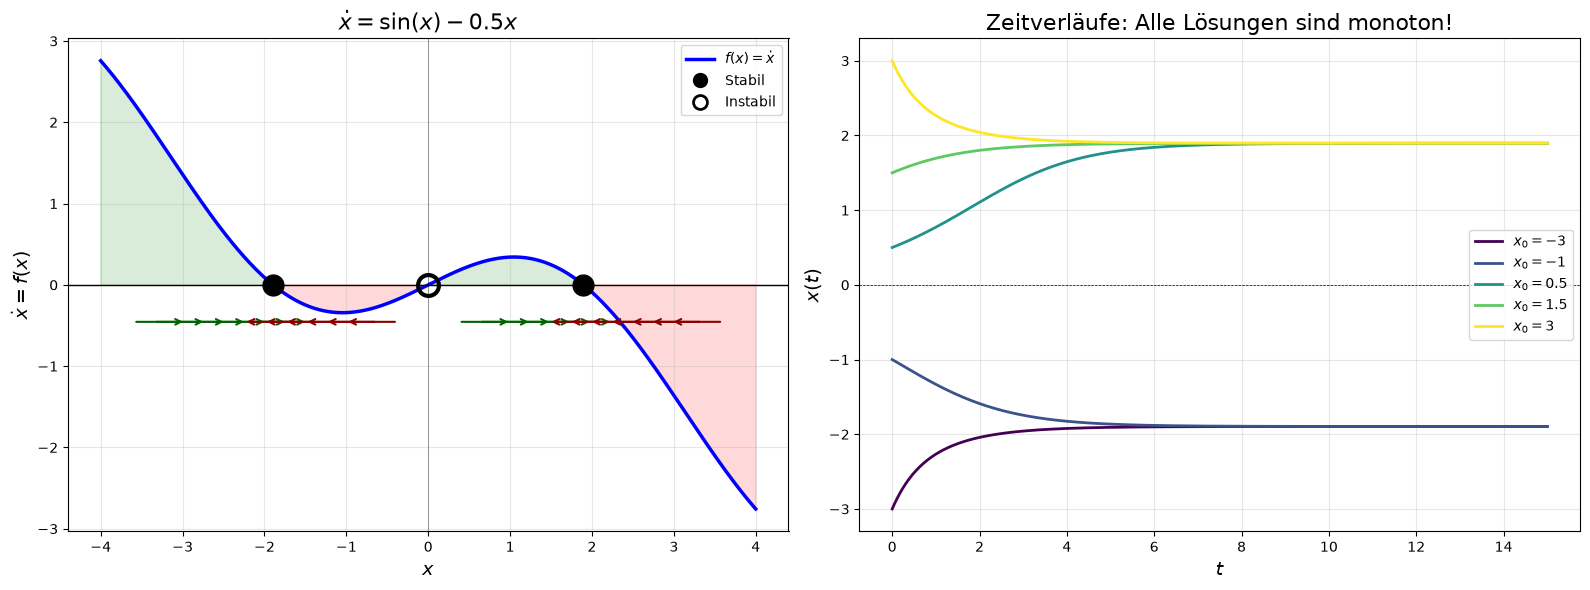

In [8]:
# Demonstration: Monotonie in 1D

def demo_monotonicity():
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    def f(x):
        return np.sin(x) - 0.5*x
    
    # Phasendiagramm
    analyze_1d_system(f, (-4, 4), title=r'$\dot{x} = \sin(x) - 0.5x$', ax=axes[0])
    
    # Zeitverläufe
    ax2 = axes[1]
    t = np.linspace(0, 15, 500)
    
    initial_conditions = [-3, -1, 0.5, 1.5, 3]
    colors = plt.cm.viridis(np.linspace(0, 1, len(initial_conditions)))
    
    for x0, color in zip(initial_conditions, colors):
        sol = odeint(lambda x, t: f(x), [x0], t)
        ax2.plot(t, sol[:, 0], color=color, linewidth=2, label=f'$x_0 = {x0}$')
    
    ax2.axhline(y=0, color='k', linewidth=0.5, linestyle='--')
    ax2.set_xlabel(r'$t$')
    ax2.set_ylabel(r'$x(t)$')
    ax2.set_title('Zeitverläufe: Alle Lösungen sind monoton!')
    ax2.legend()
    
    plt.tight_layout()
    return fig

demo_monotonicity()
plt.show()

Beachte: Jede Kurve ist **monoton** - sie steigt nur oder fällt nur (oder ist konstant). Keine Oszillation möglich!

Das ist eine fundamentale topologische Einschränkung von 1D. In 2D wird das anders - dort werden Oszillationen möglich, und in 3D schließlich Chaos.

---

## 2.5 Die Bedeutung der Zeit: Schnell vs. Langsam

Ein oft übersehener Aspekt: Die grafische Analyse sagt uns nicht nur *wohin*, sondern auch *wie schnell*.

Der Wert $|f(x)|$ gibt die **Geschwindigkeit** an:
- Wo $|f(x)|$ groß ist: schnelle Dynamik
- Wo $|f(x)|$ klein ist (nahe Fixpunkten): langsame Dynamik

Das System verbringt die meiste Zeit dort, wo es langsam ist - nahe den Fixpunkten. Das erklärt, warum Systeme oft lange in metastabilen Zuständen verweilen, bevor sie "plötzlich" umschalten.

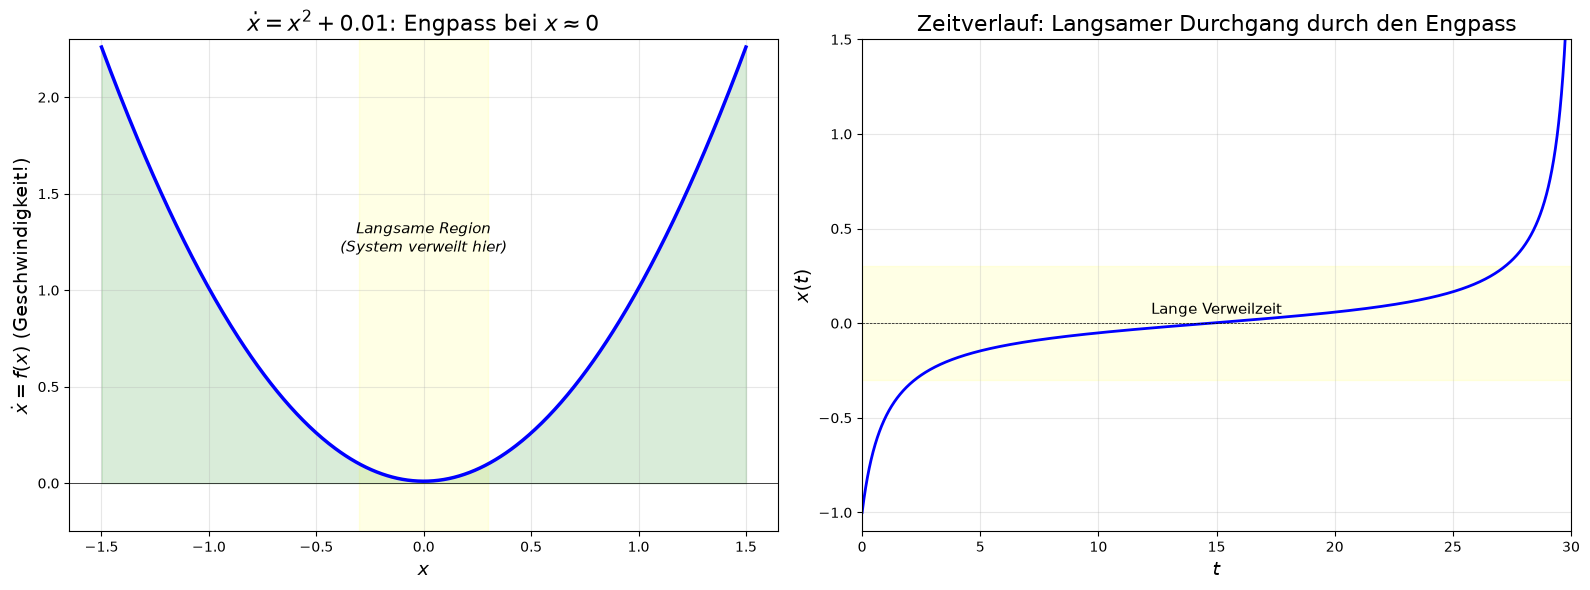

In [9]:
# Demonstration: Aufenthaltszeit und Geschwindigkeit

def demo_speed():
    # System ohne Fixpunkt, aber mit einem Engpass: Bei x ≈ 0 ist f(x) fast null.
    # Das ist der "Geist" eines Fixpunktpaars (siehe Sattelknoten-Bifurkation in Modul 5).
    # Durchgangszeit: T = π/√0.01 ≈ 31
    def f(x):
        return x**2 + 0.01

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Links: Phasendiagramm mit Geschwindigkeitsanzeige
    x = np.linspace(-1.5, 1.5, 500)
    y = f(x)

    ax1 = axes[0]
    ax1.plot(x, y, 'b-', linewidth=2.5)
    ax1.axhline(y=0, color='k', linewidth=0.5)
    ax1.fill_between(x, y, 0, alpha=0.15, color='green')

    # Markiere langsame Region
    ax1.axvspan(-0.3, 0.3, alpha=0.1, color='yellow')
    ax1.text(0, 1.2, 'Langsame Region\n(System verweilt hier)',
            ha='center', fontsize=11, style='italic')

    ax1.set_xlabel(r'$x$')
    ax1.set_ylabel(r'$\dot{x} = f(x)$ (Geschwindigkeit!)')
    ax1.set_title(r'$\dot{x} = x^2 + 0.01$: Engpass bei $x \approx 0$')
    ax1.set_ylim(-0.25, 2.3)

    # Rechts: Zeitverlauf (die Lösung divergiert bei t ≈ 30.4)
    ax2 = axes[1]
    t = np.linspace(0, 30, 2000)

    sol = odeint(lambda x, t: f(x), [-1], t, rtol=1e-10, atol=1e-10)
    ax2.plot(t, sol[:, 0], 'b-', linewidth=2)

    ax2.axhline(y=0, color='k', linewidth=0.5, linestyle='--')
    ax2.axhspan(-0.3, 0.3, alpha=0.1, color='yellow')
    ax2.text(15, 0.05, 'Lange Verweilzeit', ha='center', fontsize=11)

    ax2.set_xlabel(r'$t$')
    ax2.set_ylabel(r'$x(t)$')
    ax2.set_title('Zeitverlauf: Langsamer Durchgang durch den Engpass')
    ax2.set_xlim(0, 30)
    ax2.set_ylim(-1.1, 1.5)

    plt.tight_layout()
    return fig

demo_speed()
plt.show()


---

## 2.6 Zusammenfassung

### Kernkonzepte

1. **Grafische Analyse**: Zeichne $f(x)$, lies Fixpunkte und Flussrichtung ab.

2. **Stabilität**: $f'(x^*) < 0$ → stabil, $f'(x^*) > 0$ → instabil.

3. **Potentiale**: Für Gradientensysteme $\dot{x} = -V'(x)$: Minima sind stabil, Maxima instabil.

4. **Monotonie**: In 1D sind alle Trajektorien monoton → kein Chaos möglich.

5. **Geschwindigkeit**: $|f(x)|$ gibt die Geschwindigkeit an; nahe Fixpunkten ist sie klein.

### Was kommt

Im nächsten Modul springen wir auf **2D**: Hier werden Oszillationen möglich, und die Klassifikation der Fixpunkte wird reichhaltiger. Knoten, Sättel, Spiralen, Zentren - ein ganzer Zoo von Verhaltensweisen.

---

## Übungen

### Übung 2.1
Analysiere $\dot{x} = x(2-x)(x-1)$ grafisch. Finde alle Fixpunkte und bestimme ihre Stabilität.

### Übung 2.2
Für $\dot{x} = r - x^2$: Bei welchem Wert von $r$ ändert sich die Anzahl der Fixpunkte? Was passiert qualitativ?

### Übung 2.3
Finde das Potential $V(x)$ für $\dot{x} = \sin(x)$. Skizziere $V(x)$ und erkläre die Stabilität aller Fixpunkte.

### Übung 2.4 (Reflexion)
Warum ist das Konzept des Potentials so nützlich? In welchen physikalischen Systemen taucht es auf? Wann existiert es *nicht*?

In [10]:
# Raum für deine Lösungen

